# Caracteristicas temporales sin fuga
Construye variables usando solo informacion disponible hasta cada fecha y define como objetivo el TSI del siguiente dia dentro de cada fuente.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
INPUT = PROJECT_ROOT / 'data' / '03_analysis_output' / 'indicador_tsi' / 'tsi_provisional_diario.csv'
OUTPUT_DIR = PROJECT_ROOT / 'data' / '04_model_output' / 'features'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
tsi = pd.read_csv(INPUT, parse_dates=['fecha']).sort_values(['fuente', 'fecha']).reset_index(drop=True)
tsi.shape

(9757, 9)

In [3]:
grouped = tsi.groupby('fuente', group_keys=False)
tsi['dia_semana'] = tsi['fecha'].dt.dayofweek
tsi['mes'] = tsi['fecha'].dt.month
tsi['es_fin_de_semana'] = tsi['dia_semana'].isin([5, 6]).astype(int)
tsi['tsi_lag_1'] = grouped['tsi_provisional_media'].shift(1)
tsi['tsi_lag_7'] = grouped['tsi_provisional_media'].shift(7)
tsi['delta_1'] = tsi['tsi_provisional_media'] - tsi['tsi_lag_1']
tsi['media_movil_3'] = grouped['tsi_provisional_media'].transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
tsi['media_movil_7'] = grouped['tsi_provisional_media'].transform(lambda s: s.shift(1).rolling(7, min_periods=3).mean())
tsi['desviacion_movil_7'] = grouped['tsi_provisional_media'].transform(lambda s: s.shift(1).rolling(7, min_periods=3).std())
tsi['objetivo_tsi_siguiente'] = grouped['tsi_provisional_media'].shift(-1)
features = tsi.dropna(subset=['objetivo_tsi_siguiente', 'tsi_lag_1', 'media_movil_3']).copy()
display(features.head())
print('filas_features=' + str(len(features)))

,ciudad,fuente,metrica_principal,fecha,observaciones,tsi_provisional_media,tsi_provisional_minimo,tsi_provisional_maximo,direccion,dia_semana,mes,es_fin_de_semana,tsi_lag_1,tsi_lag_7,delta_1,media_movil_3,media_movil_7,desviacion_movil_7,objetivo_tsi_siguiente
2,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-11,1,35.697024,35.697024,35.697024,lower_is_better,1,8,0,61.116274,NaN,-25.419250,31.903981,NaN,NaN,50.927190
3,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-12,1,50.927190,50.927190,50.927190,lower_is_better,2,8,0,35.697024,NaN,15.230166,33.168329,33.168329,29.294263,52.911582
4,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-13,1,52.911582,52.911582,52.911582,lower_is_better,3,8,0,50.927190,NaN,1.984392,49.246830,37.608044,25.513660,46.497098
5,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-14,1,46.497098,46.497098,46.497098,lower_is_better,4,8,0,52.911582,NaN,-6.414484,46.511932,40.668752,23.131143,60.407493
6,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-15,1,60.407493,60.407493,60.407493,lower_is_better,5,8,1,46.497098,NaN,13.910395,50.111957,41.640143,20.825500,83.706542


filas_features=9742


In [4]:
feature_summary = features.groupby('fuente', as_index=False).agg(
    filas=('objetivo_tsi_siguiente', 'size'),
    fecha_minima=('fecha', 'min'),
    fecha_maxima=('fecha', 'max'),
    nulos_lag_7=('tsi_lag_7', lambda values: int(values.isna().sum())),
    media_objetivo=('objetivo_tsi_siguiente', 'mean'),
)
display(feature_summary)

,fuente,filas,fecha_minima,fecha_maxima,nulos_lag_7,media_objetivo
0,istanbul_traffic_index,3329,2015-08-11,2024-10-17,5,54.175932
1,madrid_traffic_points,28,2022-12-03,2022-12-30,5,98.610336
2,metr_la,116,2012-03-03,2012-06-26,5,76.638055
3,pems_bay,178,2017-01-03,2017-06-29,5,73.552044
4,sao_paulo_cet,6091,2001-01-04,2018-09-29,5,94.243048


c:\Users\REYES\OneDrive\Desktop\terminado\portafolio data science\TSI\data\04_model_output\features\tsi_daily_features.parquet


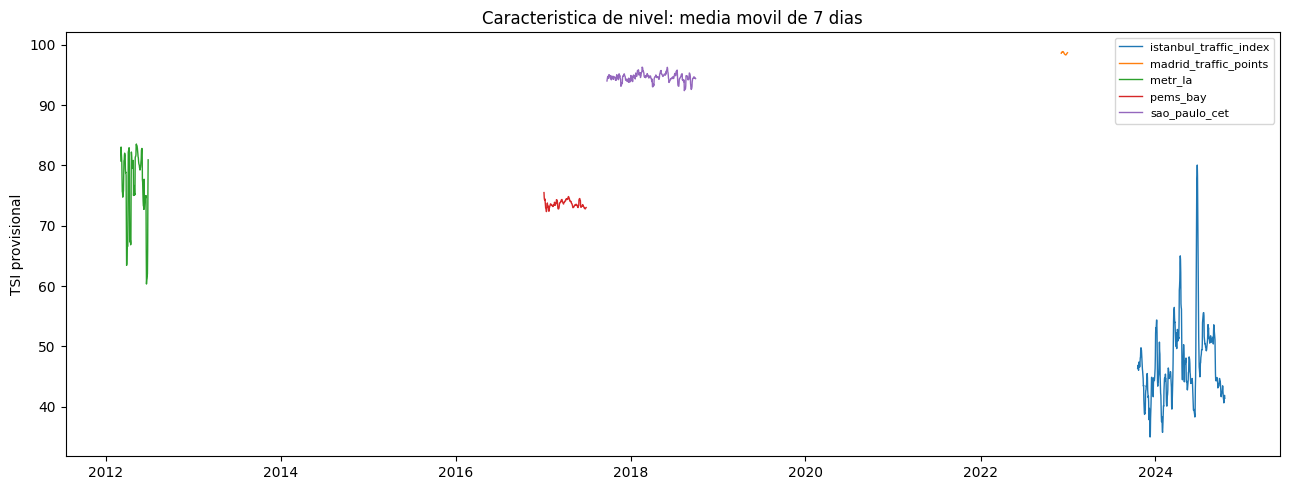

In [5]:
output_path = OUTPUT_DIR / 'tsi_daily_features.parquet'
features.to_parquet(output_path, index=False)
print(output_path)
fig, ax = plt.subplots(figsize=(13, 5))
for source, group in features.groupby('fuente'):
    sample = group.sort_values('fecha').tail(365)
    ax.plot(sample['fecha'], sample['media_movil_7'], linewidth=1, label=source)
ax.set_title('Caracteristica de nivel: media movil de 7 dias')
ax.set_ylabel('TSI provisional')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Control de fuga
Las ventanas usan `shift(1)` antes de calcular medias y desviaciones. El objetivo usa `shift(-1)` y nunca entra como predictor. La particion temporal y el umbral de clasificacion se calcularan despues, usando solo entrenamiento.